### imports y configuración

In [1]:
import os, warnings
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["LOKY_MAX_CPU_COUNT"] = "4"
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

GOLD_DIR = Path("./data/gold")
SILVER_DIR = Path("./data/silver")
RANDOM_STATE = 42
HIGH_RISK_COUNTRIES = ["KY", "VG", "PA"]
MIN_TX_PER_CUSTOMER = 3   # clientes con menos transacciones se excluyen del clustering

### construcción de features por cliente

In [2]:
def build_customer_features(df: pd.DataFrame, high_risk_countries=HIGH_RISK_COUNTRIES) -> pd.DataFrame:
    d = df.copy()
    d["timestamp"] = pd.to_datetime(d["timestamp"])
    d["is_smurfing_int"] = d["is_smurfing"].astype(int)
    d["is_night"] = d["timestamp"].dt.hour.between(0, 5).astype(int)
    d["date"] = d["timestamp"].dt.normalize()

    f = (
        d.groupby("customer_id")
        .agg(
            tx_count=("transaction_id", "count"),
            active_days=("date", "nunique"),
            avg_amount=("amount_USD", "mean"),
            std_amount=("amount_USD", "std"),
            max_amount=("amount_USD", "max"),
            max_accum_window=("accumulated_amount_window", "max"),
            max_tx_in_window=("tx_count_window", "max"),
            smurfing_tx=("is_smurfing_int", "sum"),
            night_ratio=("is_night", "mean"),
            unique_receivers=("merchant_or_receiver", "nunique"),
            unique_channels=("channel", "nunique"),
            customer_country=("customer_country", "first"),
            customer_activity=("customer_activity", "first"),
        )
        .reset_index()
    )

    f["amount_cv"] = (f["std_amount"] / f["avg_amount"]).fillna(0)
    f["tx_per_active_day"] = f["tx_count"] / f["active_days"]
    f["smurfing_ratio"] = f["smurfing_tx"] / f["tx_count"]
    f["receiver_dispersion"] = f["unique_receivers"] / f["tx_count"]
    f["is_high_risk_country"] = f["customer_country"].isin(high_risk_countries).astype(int)
    return f.drop(columns=["std_amount"])

### carga, features y diagnóstico de sesgo

In [3]:
df_m1 = pd.read_csv(GOLD_DIR / "dataset_riesgo_laft_gold_modulo1.csv", encoding="utf-8")
df_feat = build_customer_features(df_m1)

# Clientes con muy poca historia no se pueden segmentar de forma confiable
df_model = df_feat[df_feat["tx_count"] >= MIN_TX_PER_CUSTOMER].reset_index(drop=True)
print(f"Clientes totales: {len(df_feat)} | usados en clustering: {len(df_model)}")

# Columnas con sesgo fuerte -> log1p ; columnas ya acotadas -> sin log
LOG_COLS = ["tx_count", "tx_per_active_day", "avg_amount", "max_amount",
            "max_accum_window", "max_tx_in_window", "amount_cv"]
RATIO_COLS = ["smurfing_ratio", "night_ratio", "receiver_dispersion"]
FEATURE_COLS = LOG_COLS + RATIO_COLS

print("\nSesgo (skew) antes del log:")
print(df_model[FEATURE_COLS].skew().round(2))

print("\nSesgo después del log:")
print(np.log1p(df_model[LOG_COLS]).skew().round(2))

# Correlaciones altas = información redundante
corr = df_model[FEATURE_COLS].corr()
pares = (corr.where(np.triu(np.ones(corr.shape), 1).astype(bool))
             .stack().loc[lambda s: s.abs() > 0.85])
print("\nPares con |corr| > 0.85:\n", pares)

Clientes totales: 600 | usados en clustering: 600

Sesgo (skew) antes del log:
tx_count                0.30
tx_per_active_day       3.02
avg_amount              2.86
max_amount              3.66
max_accum_window       10.32
max_tx_in_window        8.91
amount_cv               2.63
smurfing_ratio         11.14
night_ratio             0.45
receiver_dispersion   -10.15
dtype: float64

Sesgo después del log:
tx_count            -0.36
tx_per_active_day    2.30
avg_amount           0.55
max_amount           1.60
max_accum_window     1.29
max_tx_in_window     4.70
amount_cv            2.27
dtype: float64

Pares con |corr| > 0.85:
 avg_amount        max_amount             0.874894
max_amount        amount_cv              0.908768
max_accum_window  max_tx_in_window       0.874342
                  smurfing_ratio         0.930674
                  receiver_dispersion   -0.917862
max_tx_in_window  smurfing_ratio         0.925780
                  receiver_dispersion   -0.897943
smurfing_ratio    

### preprocesamiento y función de entrenamiento

In [4]:
def make_preprocessor():
    log_pipe = Pipeline([
        ("log", FunctionTransformer(np.log1p, validate=False)),
        ("scale", StandardScaler()),
    ])
    return ColumnTransformer(
        [("log", log_pipe, LOG_COLS),
         ("ratio", "passthrough", RATIO_COLS)]  # ya están en 0-1
    )

def fit_kmeans(X_scaled, k, seed=RANDOM_STATE):
    return KMeans(n_clusters=k, random_state=seed, n_init=20).fit(X_scaled)

X_scaled = make_preprocessor().fit_transform(df_model[FEATURE_COLS])

### evaluación de K con varios criterios

,k,inertia,silhouette
0,2,2949.218,0.511
1,3,2287.364,0.496
2,4,1808.889,0.239
3,5,1528.594,0.237
4,6,1350.177,0.257
5,7,1225.629,0.250
6,8,1141.952,0.239


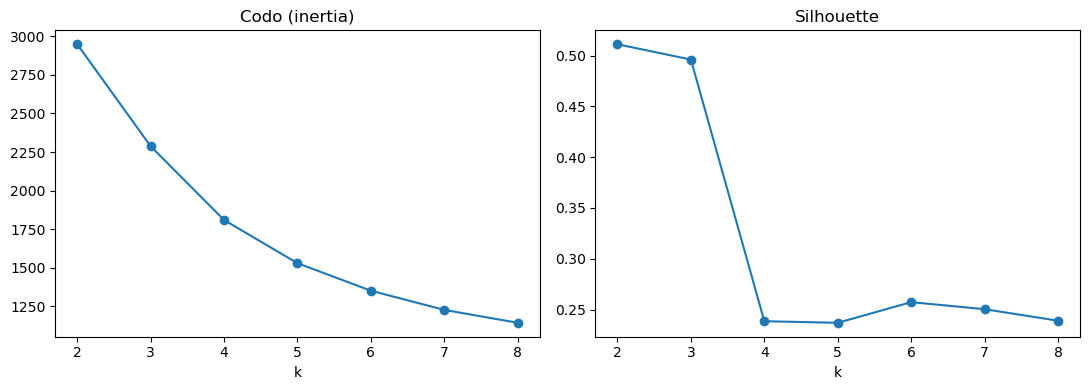

In [5]:
def evaluate_k(X, k_range=range(2, 9)):
    rows = []
    for k in k_range:
        model = fit_kmeans(X, k)
        rows.append({
            "k": k,
            "inertia": model.inertia_,
            "silhouette": silhouette_score(X, model.labels_),
        })
    return pd.DataFrame(rows)

df_k = evaluate_k(X_scaled)
display(df_k.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(df_k["k"], df_k["inertia"], "o-");    axes[0].set_title("Codo (inertia)")
axes[1].plot(df_k["k"], df_k["silhouette"], "o-"); axes[1].set_title("Silhouette")
for ax in axes: ax.set_xlabel("k")
plt.tight_layout(); plt.show()

### decisión explícita de K

In [6]:

K_FINAL = int(df_k.loc[df_k["silhouette"].idxmax(), "k"])  
print("K sugerido por silhouette:", K_FINAL)

K_FINAL = 3
model = fit_kmeans(X_scaled, K_FINAL)
df_model["cluster_id"] = model.labels_

print("Clientes por cluster:")
print(df_model["cluster_id"].value_counts().sort_index())
print("\nPorcentaje:")
print((df_model["cluster_id"].value_counts(normalize=True).sort_index() * 100).round(2))
print(f"\nSilhouette con K={K_FINAL}: {silhouette_score(X_scaled, model.labels_):.3f}")

K sugerido por silhouette: 2
Clientes por cluster:
cluster_id
0    524
1      5
2     71
Name: count, dtype: int64

Porcentaje:
cluster_id
0    87.33
1     0.83
2    11.83
Name: proportion, dtype: float64

Silhouette con K=3: 0.496


### perfil de clusters y etiqueta de riesgo

In [7]:
profile = (
    df_model.groupby("cluster_id")
    .agg(
        clientes=("customer_id", "count"),
        tx_prom=("tx_count", "mean"),
        ticket_prom=("avg_amount", "mean"),
        monto_max_prom=("max_amount", "mean"),
        max_acum_ventana=("max_accum_window", "mean"),
        pct_smurfing=("smurfing_ratio", "mean"),
        pct_nocturno=("night_ratio", "mean"),
        dispersion_receptores=("receiver_dispersion", "mean"),
        pct_alta_jurisdiccion=("is_high_risk_country", "mean"),
    )
)
display(profile.round(3))

# Score de riesgo: promedio de rankings de las señales LA/FT
senales = ["pct_smurfing", "max_acum_ventana", "monto_max_prom",
           "pct_nocturno", "pct_alta_jurisdiccion"]
profile["risk_score"] = profile[senales].rank(pct=True).mean(axis=1)

# Con K=3: el menor score = bajo, el intermedio = medio, el mayor = alto
orden = profile["risk_score"].rank(method="first").astype(int)
nombres = {1: "Riesgo bajo", 2: "Riesgo medio", 3: "Riesgo alto"}
profile["nivel_riesgo"] = orden.map(nombres)

display(profile[["clientes", "risk_score", "nivel_riesgo"]].round(3))

# Asignar al dataset de clientes
df_model["nivel_riesgo"] = df_model["cluster_id"].map(profile["nivel_riesgo"])
df_model["risk_score"] = df_model["cluster_id"].map(profile["risk_score"])

,clientes,tx_prom,ticket_prom,monto_max_prom,max_acum_ventana,pct_smurfing,pct_nocturno,dispersion_receptores,pct_alta_jurisdiccion
cluster_id,,,,,,,,,
0,524,20.113,68.504,144.625,141.020,0.000,0.246,0.999,0.000
1,5,31.600,187.902,602.172,3536.506,0.292,0.595,0.613,0.000
2,71,20.056,241.908,3291.662,140.511,0.000,0.272,0.999,0.028


,clientes,risk_score,nivel_riesgo
cluster_id,,,
0,524,0.467,Riesgo bajo
1,5,0.833,Riesgo alto
2,71,0.700,Riesgo medio


### visualización con PCA

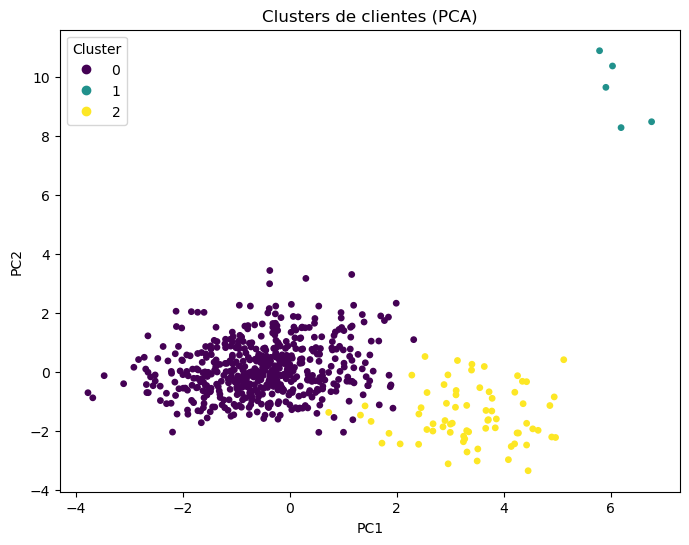

In [8]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
coords = pca.fit_transform(X_scaled)
plt.figure(figsize=(8, 6))
sc = plt.scatter(coords[:, 0], coords[:, 1], c=df_model.sort_index()["cluster_id"], cmap="viridis", s=15)
plt.legend(*sc.legend_elements(), title="Cluster")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Clusters de clientes (PCA)")
plt.show()

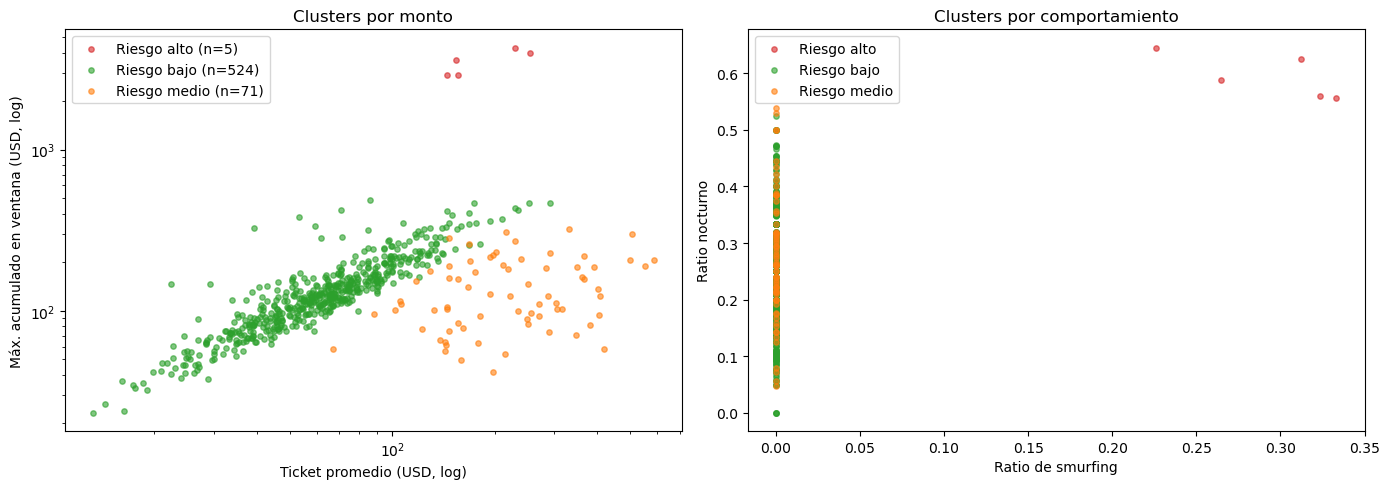

In [9]:
colores = {"Riesgo bajo": "tab:green", "Riesgo medio": "tab:orange", "Riesgo alto": "tab:red"}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfica 1: ticket promedio vs. máximo acumulado en ventana (escala log por el sesgo)
for nivel, g in df_model.groupby("nivel_riesgo"):
    axes[0].scatter(g["avg_amount"], g["max_accum_window"], s=15, alpha=0.6,
                    label=f"{nivel} (n={len(g)})", color=colores[nivel])
axes[0].set_xscale("log"); axes[0].set_yscale("log")
axes[0].set_xlabel("Ticket promedio (USD, log)")
axes[0].set_ylabel("Máx. acumulado en ventana (USD, log)")
axes[0].set_title("Clusters por monto")
axes[0].legend()

# Gráfica 2: smurfing vs. actividad nocturna
for nivel, g in df_model.groupby("nivel_riesgo"):
    axes[1].scatter(g["smurfing_ratio"], g["night_ratio"], s=15, alpha=0.6,
                    label=nivel, color=colores[nivel])
axes[1].set_xlabel("Ratio de smurfing")
axes[1].set_ylabel("Ratio nocturno")
axes[1].set_title("Clusters por comportamiento")
axes[1].legend()

plt.tight_layout(); plt.show()

In [10]:
# guardar cleintes en la capa silver
out = SILVER_DIR / "clientes_clusterizados_silver_modulo2.csv"
df_model.to_csv(out, index=False, encoding="utf-8")
print("Guardado en:", out.resolve())

Guardado en: C:\Users\Hugo\OneDrive\Documentos\MEGA\PROYECTOS\GIT-HUB\reto_analista_de_datos\data\silver\clientes_clusterizados_silver_modulo2.csv


In [11]:
# Tabla de referencia: un registro por cliente
cliente_cluster = (
    df_model[["customer_id", "cluster_id", "nivel_riesgo"]]
    .drop_duplicates(subset="customer_id")
    .set_index("customer_id")
)

# Cluster que corresponde a "Riesgo bajo"
cluster_bajo = int(
    df_model.loc[df_model["nivel_riesgo"] == "Riesgo bajo", "cluster_id"].iloc[0]
)
print("Cluster asignado a 'Riesgo bajo':", cluster_bajo)

# Aplicar al dataframe transaccional original (map conserva el número de filas)
df_consolidado = df_m1.copy()
df_consolidado["fuera_de_clustering"] = ~df_consolidado["customer_id"].isin(cliente_cluster.index)

df_consolidado["cluster_id"] = (
    df_consolidado["customer_id"].map(cliente_cluster["cluster_id"])
    .fillna(cluster_bajo)
    .astype(int)
)
df_consolidado["nivel_riesgo"] = (
    df_consolidado["customer_id"].map(cliente_cluster["nivel_riesgo"]).fillna("Riesgo bajo")
)

# Validaciones
assert len(df_consolidado) == len(df_m1), "Cambió el número de filas"
assert df_consolidado["cluster_id"].notna().all(), "Quedaron clusters vacíos"
print(f"Transacciones: {len(df_consolidado)}")
print("\nDistribución por nivel de riesgo (transacciones):")
print(df_consolidado["nivel_riesgo"].value_counts())
print("\nClientes fuera del clustering (asignados a Riesgo bajo):",
      df_consolidado.loc[df_consolidado["fuera_de_clustering"], "customer_id"].nunique())

# Guardar en la capa gold
out_path = GOLD_DIR / "dataset_riesgo_laft_gold_clustering_modulo2.csv"
df_consolidado.to_csv(out_path, index=False, encoding="utf-8")
print("\nGuardado en:", out_path.resolve())

display(df_consolidado.head())

Cluster asignado a 'Riesgo bajo': 0
Transacciones: 12121

Distribución por nivel de riesgo (transacciones):
nivel_riesgo
Riesgo bajo     10539
Riesgo medio     1424
Riesgo alto       158
Name: count, dtype: int64

Clientes fuera del clustering (asignados a Riesgo bajo): 0

Guardado en: C:\Users\Hugo\OneDrive\Documentos\MEGA\PROYECTOS\GIT-HUB\reto_analista_de_datos\data\gold\dataset_riesgo_laft_gold_clustering_modulo2.csv


,transaction_id,customer_id,timestamp,amount_USD,currency_original,merchant_or_receiver,payment_description,customer_country,customer_activity,channel,accumulated_amount_window,tx_count_window,is_smurfing,fuera_de_clustering,cluster_id,nivel_riesgo
0,TRX_000678,00a5f,2025-01-05 22:12:00,173.17,COP,REC_8628,Pago servicios,CO,Comerciante,APP,173.17,1,False,False,0,Riesgo bajo
1,TRX_001201,00a5f,2025-01-09 17:58:00,132.94,COP,REC_9133,Suscripción mensual,CO,Comerciante,APP,132.94,1,False,False,0,Riesgo bajo
2,TRX_001358,00a5f,2025-01-11 00:13:00,74.64,COP,REC_8987,Suscripción mensual,CO,Comerciante,APP,74.64,1,False,False,0,Riesgo bajo
3,TRX_001733,00a5f,2025-01-13 17:21:00,98.19,COP,REC_6373,Suscripción mensual,CO,Comerciante,APP,98.19,1,False,False,0,Riesgo bajo
4,TRX_002307,00a5f,2025-01-18 01:37:00,71.87,COP,REC_3320,Compra supermercado,CO,Comerciante,APP,71.87,1,False,False,0,Riesgo bajo


### Clientes de alto riesgo

In [12]:
clientes_alto_riesgo = df_consolidado[df_consolidado['nivel_riesgo'] == 'Riesgo alto']
display(clientes_alto_riesgo.head())

,transaction_id,customer_id,timestamp,amount_USD,currency_original,merchant_or_receiver,payment_description,customer_country,customer_activity,channel,accumulated_amount_window,tx_count_window,is_smurfing,fuera_de_clustering,cluster_id,nivel_riesgo
3678,TRX_000215,4c93d,2025-01-02 08:12:00,26.25,COP,REC_9875,Suscripción mensual,CO,Asalariado,WEB,26.25,1,False,False,1,Riesgo alto
3679,TRX_000616,4c93d,2025-01-05 09:22:00,87.31,COP,REC_2897,Restaurante,CO,Asalariado,WEB,87.31,1,False,False,1,Riesgo alto
3680,TRX_000685,4c93d,2025-01-06 00:51:00,67.32,COP,REC_2375,Transferencia familiar,CO,Asalariado,WEB,67.32,1,False,False,1,Riesgo alto
3681,TRX_000768,4c93d,2025-01-06 17:33:00,83.87,COP,REC_2755,Compra supermercado,CO,Asalariado,WEB,83.87,1,False,False,1,Riesgo alto
3682,TRX_001956,4c93d,2025-01-15 06:06:00,65.26,COP,REC_2054,Compra supermercado,CO,Asalariado,WEB,65.26,1,False,False,1,Riesgo alto


### Detalle de clientes de alto riesgo

In [13]:
resumen_clientes = (
    clientes_alto_riesgo
    .groupby("customer_id")
    .agg(
        transacciones=("transaction_id", "count"),
        monto_total=("amount_USD", "sum"),
        monto_promedio=("amount_USD", "mean"),
        monto_max=("amount_USD", "max"),
        monto_min=("amount_USD", "min"),
        primer_tx=("timestamp", "min"),
        ultima_tx=("timestamp", "max")
    )
    .reset_index()
)

resumen_clientes.head()

,customer_id,transacciones,monto_total,monto_promedio,monto_max,monto_min,primer_tx,ultima_tx
0,4c93d,32,4634.85,144.839063,267.01,26.25,2025-01-02 08:12:00,2025-03-27 14:22:00
1,6142e,27,4163.14,154.190370,327.96,16.82,2025-01-06 07:36:00,2025-03-27 19:55:00
2,87be5,31,7130.10,230.003226,513.29,20.24,2025-01-07 16:56:00,2025-03-27 12:57:00
3,b4957,34,8658.13,254.650882,1422.60,86.84,2025-01-01 08:05:00,2025-03-27 11:36:00
4,b5f51,34,5298.15,155.827941,480.00,33.85,2025-01-01 05:22:00,2025-03-18 18:18:00
